# 01 - Data Analysis
Traffic dataset ko load, validate aur explore karta hai. Cleaning logic `backend/preprocessing.py` se aata hai.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'Notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from backend import preprocessing as pp, model as tm

In [2]:
raw = pp.load_raw()
raw.head()

,ID,DateTime,Junction,Vehicles
0,1,2024-01-01 00:00:00,1,16
1,2,2024-01-01 01:00:00,1,9
2,3,2024-01-01 02:00:00,1,15
3,4,2024-01-01 03:00:00,1,19
4,5,2024-01-01 04:00:00,1,11


In [3]:
clean_df, report = pp.clean(raw)
report

{'rows_in': 12000,
 'missing_values': 0,
 'unparseable_datetimes': 0,
 'duplicates_dropped': 0,
 'hourly_gaps': 0,
 'rows_out': 12000}

In [4]:
clean_df.describe()

,ID,DateTime,Junction,Vehicles
count,12000.00000,12000,12000.000000,12000.000000
mean,6000.50000,2024-03-03 11:30:00,2.500000,20.138167
min,1.00000,2024-01-01 00:00:00,1.000000,1.000000
25%,3000.75000,2024-02-01 05:45:00,1.750000,13.000000
50%,6000.50000,2024-03-03 11:30:00,2.500000,18.000000
75%,9000.25000,2024-04-03 17:15:00,3.250000,25.000000
max,12000.00000,2024-05-04 23:00:00,4.000000,71.000000
std,3464.24595,NaN,1.118081,10.032844


## Junction-wise traffic

In [5]:
clean_df.groupby('Junction')['Vehicles'].agg(['count','mean','std','min','max'])

,count,mean,std,min,max
Junction,,,,,
1,3000,16.564667,6.852698,2,46
2,3000,23.261667,9.002456,3,59
3,3000,13.013333,5.646986,1,37
4,3000,27.713000,10.589114,7,71


## Hourly pattern (peak hours)

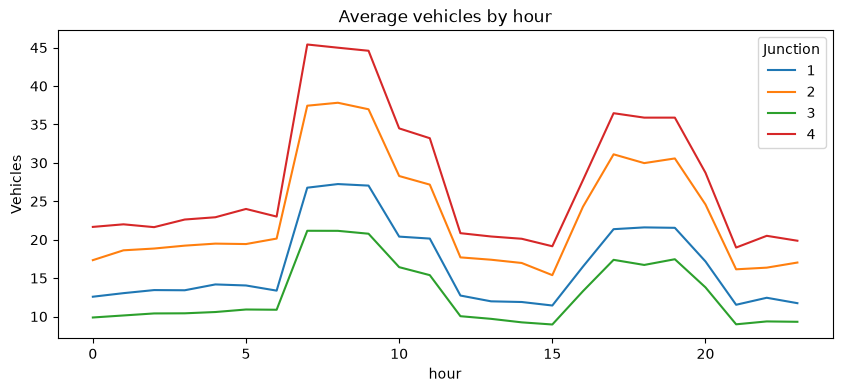

In [6]:
hourly = clean_df.assign(hour=clean_df.DateTime.dt.hour).groupby(['hour','Junction'])['Vehicles'].mean().unstack()
hourly.plot(figsize=(10,4), title='Average vehicles by hour')
plt.ylabel('Vehicles'); plt.show()

## Weekday pattern

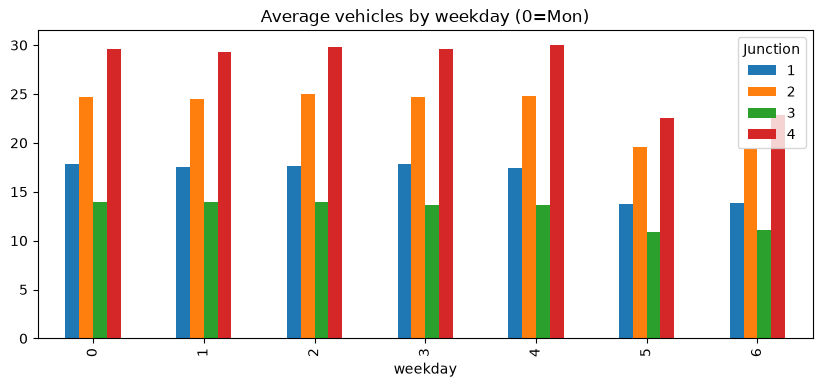

In [7]:
wk = clean_df.assign(weekday=clean_df.DateTime.dt.dayofweek).groupby(['weekday','Junction'])['Vehicles'].mean().unstack()
wk.plot(kind='bar', figsize=(10,4), title='Average vehicles by weekday (0=Mon)')
plt.show()

## Feature engineering aur processed data save

In [8]:
features = pp.build_features(clean_df)
print(features.shape)
features.head()

(11328, 15)


,ID,DateTime,Junction,Vehicles,hour,weekday,is_weekend,is_peak_hour,lag_1,lag_2,lag_3,lag_24,lag_168,roll_mean_3,roll_mean_24
0,169,2024-01-08 00:00:00,1,20,0,0,0,0,11.0,15.0,12.0,12.0,16.0,12.666667,14.083333
1,170,2024-01-08 01:00:00,1,5,1,0,0,0,20.0,11.0,15.0,9.0,9.0,15.333333,14.416667
2,171,2024-01-08 02:00:00,1,13,2,0,0,0,5.0,20.0,11.0,13.0,15.0,12.000000,14.250000
3,172,2024-01-08 03:00:00,1,16,3,0,0,0,13.0,5.0,20.0,6.0,19.0,12.666667,14.250000
4,173,2024-01-08 04:00:00,1,19,4,0,0,0,16.0,13.0,5.0,5.0,11.0,11.333333,14.666667


In [9]:
pp.run_preprocessing()

{'rows_in': 12000,
 'missing_values': 0,
 'unparseable_datetimes': 0,
 'duplicates_dropped': 0,
 'hourly_gaps': 0,
 'rows_out': 12000,
 'feature_rows': 11328}